# Real-Time Content Moderator — Clustering (Review 2)

## Purpose
This notebook implements the two required unsupervised algorithms using the **same Civil Comments CSV** used in Review 1:
1. K-Means clustering (including an Elbow curve).
2. Agglomerative Hierarchical Clustering (including linkage comparison and dendrograms).

It reports Silhouette Score, Davies–Bouldin Index and Calinski–Harabasz Index; creates PCA visualizations for both algorithms; and creates a t-SNE visualization for K-Means.

**Important methodology rule:** the `target` / `is_toxic` labels are not part of the input features and are not provided to either clustering algorithm. They are joined back only after clustering for optional descriptive validation.

**Scalability note:** Agglomerative clustering requires pairwise distance calculations. To keep the notebook practical on student hardware, all clustering comparisons use a reproducible 3,000-row sample from the provided 50,000-row file; dendrograms use a separate 350-row subset, and t-SNE uses 1,500 rows. The sample sizes and random seed are printed below.

**Academic integrity note:** this notebook provides code scaffolding and measured outputs. The team must write its own evidence-based visual and metric interpretation before submission.

## 1. Imports and reproducibility

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
pd.set_option('display.max_columns', 50)

## 2. Load and audit the same dataset

In [2]:
DATA_CANDIDATES = [
    '../data/train_sample_50k.csv',
    'data/train_sample_50k.csv',
    '../../data/train_sample_50k.csv',
]
DATA_PATH = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError('Could not find data/train_sample_50k.csv. Run from repository root or notebooks/.')

df = pd.read_csv(DATA_PATH)
print('Dataset path:', os.path.abspath(DATA_PATH))
print('Dataset shape:', df.shape)
print('Duplicate rows:', int(df.duplicated().sum()))
print('Missing comment_text:', int(df['comment_text'].isna().sum()))
df[['target', 'comment_text', 'created_date']].head()

Dataset path: C:\Users\Hello Frnd\.gemini\antigravity\scratch\ML_Project\data\train_sample_50k.csv
Dataset shape: (50000, 45)
Duplicate rows: 0
Missing comment_text: 1


,target,comment_text,created_date
0,0.166667,What a breathe of fresh air to have someone wh...,2016-11-11 17:46:40.531665+00
1,0.600000,Your jewish friends were the ones who told you...,2016-12-26 15:45:07.874526+00
2,0.000000,Possible collusion by Trump and his affiliates...,2017-06-13 16:05:45.932626+00
3,0.000000,Exactly. We need a % of GDP spending cap at t...,2017-08-20 21:40:26.704482+00
4,0.000000,"By your own comment, even if some of them vote...",2016-10-27 18:07:47.993026+00


## 3. Build clustering features (excluding labels)

We construct structural comment features similar to those used in Review 1, but clustering does not use a target column. Count-like features receive a `log1p` transform before `RobustScaler` because comment lengths and punctuation counts are strongly right-skewed; this reduces, but does not eliminate, the effect of extreme values. Do not add `target`, toxicity subtype labels, identity annotation columns or `is_toxic` to `cluster_features`.

In [3]:
text = df['comment_text'].fillna('').astype(str)
features = pd.DataFrame(index=df.index)
features['comment_length'] = text.str.len().astype(float)
features['word_count'] = text.str.split().str.len().fillna(0).astype(float)
features['uppercase_ratio'] = text.str.count(r'[A-Z]') / features['comment_length'].clip(lower=1)
features['exclamation_count'] = text.str.count('!').astype(float)
features['question_count'] = text.str.count(r'\?').astype(float)
features['special_character_count'] = text.str.count(r'[^A-Za-z0-9\s]').astype(float)
features['digit_count'] = text.str.count(r'\d').astype(float)

def unique_word_ratio(value):
    words = str(value).lower().split()
    return len(set(words)) / len(words) if words else 0.0

features['unique_word_ratio'] = text.map(unique_word_ratio).astype(float)
features['average_word_length'] = features['comment_length'] / features['word_count'].clip(lower=1)
features['sentence_count'] = text.map(lambda value: max(1, sum(1 for part in str(value).split('.') if part.strip()))).astype(float)

# Log-transform nonnegative, long-tailed count/length features for clustering only.
log_columns = [
    'comment_length', 'word_count', 'exclamation_count', 'question_count',
    'special_character_count', 'digit_count', 'average_word_length', 'sentence_count'
]
features[log_columns] = np.log1p(features[log_columns].clip(lower=0))

cluster_features = features.columns.tolist()
print('Clustering feature columns:', cluster_features)
print('Forbidden label columns present in X? ', any(c in cluster_features for c in ['target', 'is_toxic', 'severe_toxicity', 'obscene', 'insult', 'threat']))
features.describe().T.round(3)

Clustering feature columns: ['comment_length', 'word_count', 'uppercase_ratio', 'exclamation_count', 'question_count', 'special_character_count', 'digit_count', 'unique_word_ratio', 'average_word_length', 'sentence_count']
Forbidden label columns present in X?  False


,count,mean,std,min,25%,50%,75%,max
comment_length,50000.0,5.253,1.040,0.000,4.564,5.318,6.040,6.940
word_count,50000.0,3.538,0.990,0.000,2.890,3.584,4.290,5.394
uppercase_ratio,50000.0,0.037,0.047,0.000,0.018,0.028,0.042,1.000
exclamation_count,50000.0,0.116,0.336,0.000,0.000,0.000,0.000,4.673
question_count,50000.0,0.242,0.435,0.000,0.000,0.000,0.693,3.611
special_character_count,50000.0,2.049,0.845,0.000,1.386,2.079,2.639,5.717
digit_count,50000.0,0.385,0.759,0.000,0.000,0.000,0.000,5.580
unique_word_ratio,50000.0,0.868,0.108,0.000,0.786,0.877,0.966,1.000
average_word_length,50000.0,1.920,0.164,0.000,1.854,1.907,1.962,5.421
sentence_count,50000.0,1.347,0.554,0.693,0.693,1.386,1.792,3.689


## 4. Reproducible clustering sample and scaling

The same source CSV is used, but a deterministic sample is used for computational feasibility. Ground-truth labels are stored separately and never passed to `fit` or `fit_predict`.

In [4]:
CLUSTER_SAMPLE_SIZE = min(3000, len(df))
sample_idx = df.sample(n=CLUSTER_SAMPLE_SIZE, random_state=RANDOM_STATE).index
X_cluster_raw = features.loc[sample_idx, cluster_features].copy()
# Retained separately for post-fit descriptive validation only; never included in X_cluster_raw.
target_for_validation = df.loc[sample_idx, 'target'].astype(float).to_numpy()
is_toxic_for_validation = (target_for_validation >= 0.5).astype(int)

scaler = RobustScaler()
X_cluster = scaler.fit_transform(X_cluster_raw)
print('Original rows:', len(df))
print('Rows used for clustering metrics and PCA:', len(X_cluster))
print('Feature matrix shape:', X_cluster.shape)
print('Dendrogram sample planned:', min(350, len(X_cluster)))
print('t-SNE sample planned:', min(1500, len(X_cluster)))

Original rows: 50000
Rows used for clustering metrics and PCA: 3000
Feature matrix shape: (3000, 10)
Dendrogram sample planned: 350
t-SNE sample planned: 1500


## 5. K-Means: Elbow curve

Fit K-Means for candidate `k` values and plot inertia. The code also prints a reproducible maximum-distance-from-chord knee suggestion. This is a heuristic aid rather than a replacement for the team's own inspection of the plotted elbow.

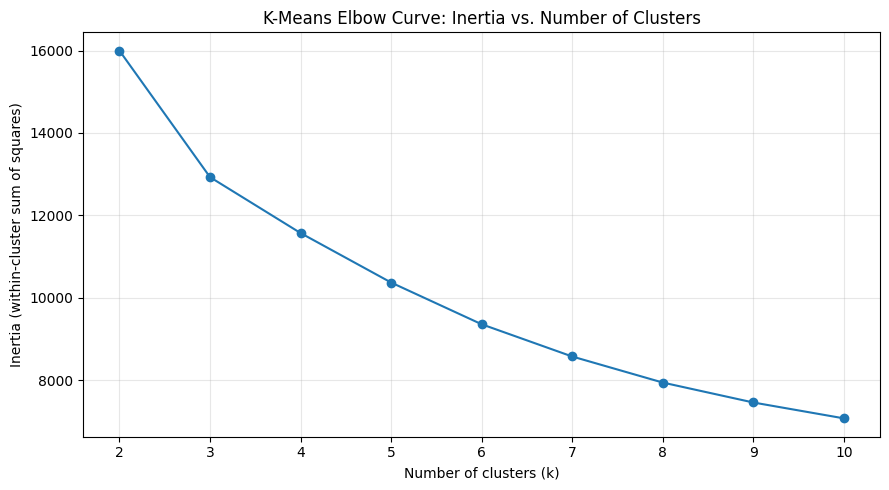

Heuristic elbow suggestion: 5


,k,Inertia,Chord distance
0,2,15996.988,0.000
1,3,12927.110,0.219
2,4,11569.892,0.246
3,5,10368.542,0.256
4,6,9355.382,0.244
5,7,8572.576,0.207
6,8,7940.018,0.153
7,9,7456.039,0.082
8,10,7070.956,0.000


In [5]:
k_values = list(range(2, 11))
inertias = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    km.fit(X_cluster)
    inertias.append(float(km.inertia_))

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker='o')
plt.title('K-Means Elbow Curve: Inertia vs. Number of Clusters')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Normalize axes and find maximum deviation from the straight line joining the endpoints.
x_norm = (np.asarray(k_values, dtype=float) - min(k_values)) / (max(k_values) - min(k_values))
y_values = np.asarray(inertias, dtype=float)
y_norm = (y_values - y_values.min()) / (y_values.max() - y_values.min() + 1e-12)
line_y = 1.0 - x_norm
knee_distances = np.abs(line_y - y_norm)
suggested_k = int(k_values[int(np.argmax(knee_distances))])
elbow_table = pd.DataFrame({'k': k_values, 'Inertia': inertias, 'Chord distance': knee_distances})
print('Heuristic elbow suggestion:', suggested_k)
elbow_table.round(3)

## 6. Fit K-Means and Agglomerative Clustering

The heuristic suggestion above is used as a reproducible starting cluster count for both main algorithms, so metrics can be compared with the same `k`. The team should inspect the Elbow curve and document its own justification before the review.

In [6]:
SELECTED_K = suggested_k
kmeans_model = KMeans(n_clusters=SELECTED_K, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans_model.fit_predict(X_cluster)

agglomerative_model = AgglomerativeClustering(n_clusters=SELECTED_K, linkage='ward', metric='euclidean')
agglomerative_labels = agglomerative_model.fit_predict(X_cluster)

print('Selected k:', SELECTED_K)
print('K-Means clusters:', dict(pd.Series(kmeans_labels).value_counts().sort_index()))
print('Agglomerative (Ward) clusters:', dict(pd.Series(agglomerative_labels).value_counts().sort_index()))

Selected k: 5
K-Means clusters: {0: np.int64(1334), 1: np.int64(260), 2: np.int64(1249), 3: np.int64(2), 4: np.int64(155)}
Agglomerative (Ward) clusters: {0: np.int64(1197), 1: np.int64(385), 2: np.int64(228), 3: np.int64(1188), 4: np.int64(2)}


## 7. Required internal clustering metrics

All three required metrics are reported for both main algorithms on the same sampled feature matrix. Silhouette is estimated using the same reproducible 2,000-row metric sample when more than 2,000 rows are available; Davies–Bouldin and Calinski–Harabasz use the full 3,000-row clustering sample.

In [7]:
def clustering_metrics(X, labels, algorithm_name):
    n_labels = len(np.unique(labels))
    if n_labels < 2 or n_labels >= len(labels):
        silhouette = np.nan
    else:
        silhouette = silhouette_score(
            X, labels,
            sample_size=min(2000, len(labels)),
            random_state=RANDOM_STATE
        )
    return {
        'Algorithm': algorithm_name,
        'Clusters': n_labels,
        'Silhouette Score (sampled)': silhouette,
        'Davies-Bouldin Index': davies_bouldin_score(X, labels),
        'Calinski-Harabasz Index': calinski_harabasz_score(X, labels)
    }

main_metrics_df = pd.DataFrame([
    clustering_metrics(X_cluster, kmeans_labels, 'K-Means'),
    clustering_metrics(X_cluster, agglomerative_labels, 'Agglomerative (Ward)')
])
main_metrics_df.round(4)

,Algorithm,Clusters,Silhouette Score (sampled),Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,5,0.2426,1.0716,710.5729
1,Agglomerative (Ward),5,0.1838,1.1975,582.5522


## 8. Compare hierarchical linkage strategies

Ward, complete and average linkages are fitted with the same cluster count and data sample. This produces a like-for-like metrics table in addition to the required dendrogram visualization.

In [8]:
linkage_results = []
linkage_labels = {}
for method in ['ward', 'complete', 'average']:
    model = AgglomerativeClustering(n_clusters=SELECTED_K, linkage=method, metric='euclidean')
    labels = model.fit_predict(X_cluster)
    linkage_labels[method] = labels
    linkage_results.append(clustering_metrics(X_cluster, labels, f'Agglomerative ({method.title()})'))
linkage_comparison_df = pd.DataFrame(linkage_results)
linkage_comparison_df.round(4)

,Algorithm,Clusters,Silhouette Score (sampled),Davies-Bouldin Index,Calinski-Harabasz Index
0,Agglomerative (Ward),5,0.1838,1.1975,582.5522
1,Agglomerative (Complete),5,0.7328,0.3006,135.7992
2,Agglomerative (Average),5,0.7554,0.1358,121.1739


## 9. Dendrograms (Ward, Complete and Average)

A separate fixed-size sample is used so the dendrogram is legible and can be computed on standard student hardware. These dendrograms are illustrative of hierarchical structure; the main evaluation metrics above use the reproducible clustering sample.

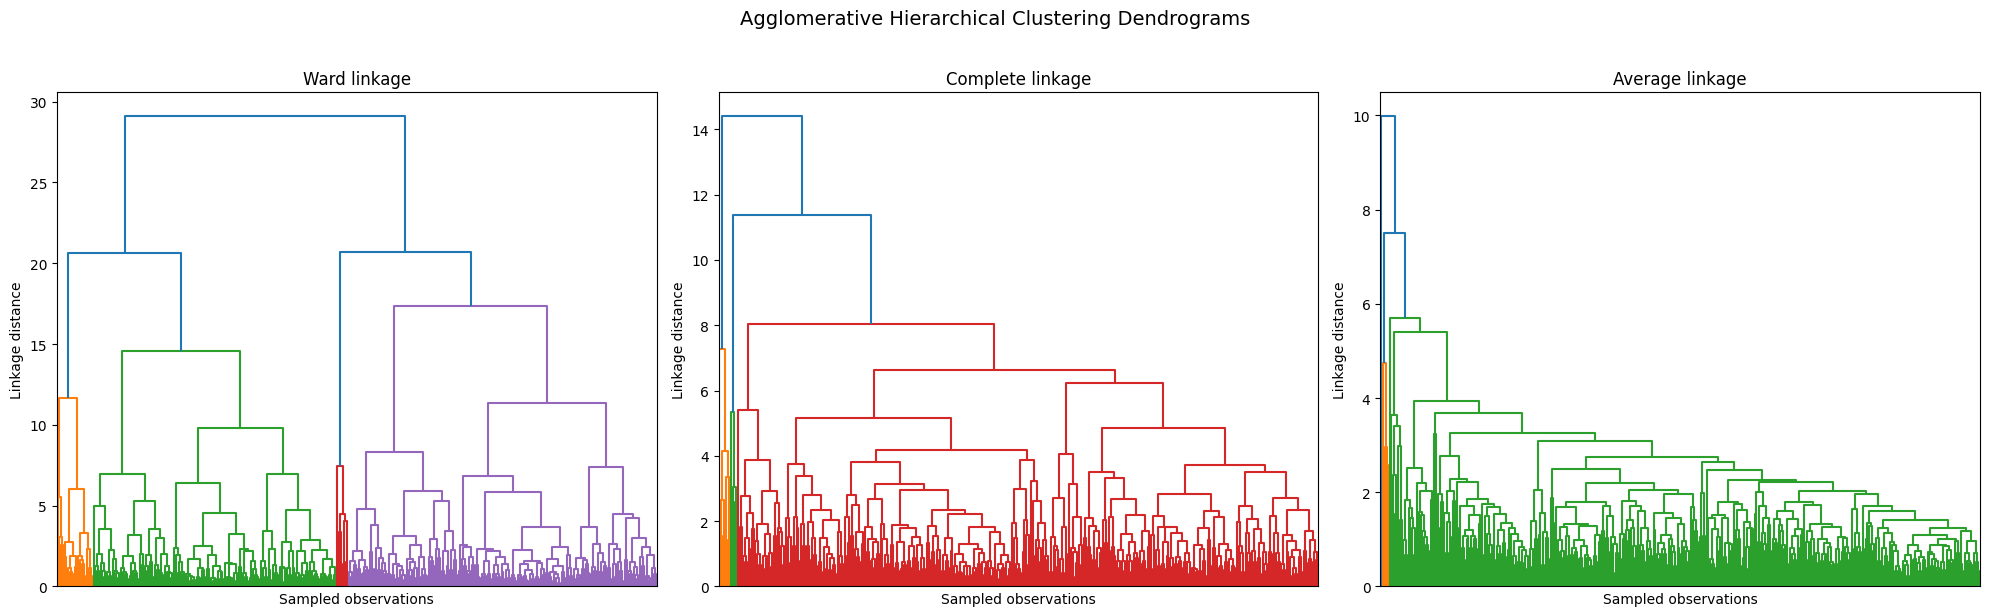

In [9]:
DENDROGRAM_SAMPLE_SIZE = min(350, len(X_cluster))
rng = np.random.default_rng(RANDOM_STATE)
dendro_indices = np.sort(rng.choice(len(X_cluster), size=DENDROGRAM_SAMPLE_SIZE, replace=False))
X_dendro = X_cluster[dendro_indices]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, method in zip(axes, ['ward', 'complete', 'average']):
    Z = linkage(X_dendro, method=method, metric='euclidean')
    dendrogram(Z, ax=ax, no_labels=True, color_threshold=None)
    ax.set_title(f'{method.title()} linkage')
    ax.set_xlabel('Sampled observations')
    ax.set_ylabel('Linkage distance')
fig.suptitle('Agglomerative Hierarchical Clustering Dendrograms', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## 10. PCA visualization for each required algorithm

PCA is fitted on the scaled clustering feature matrix, reduced to two components, and used only for visualization. Cluster colors are generated from the model labels, not from toxicity labels.

PCA explained variance ratio: [0.3907 0.2314]
Total variance retained by two components: 0.6221


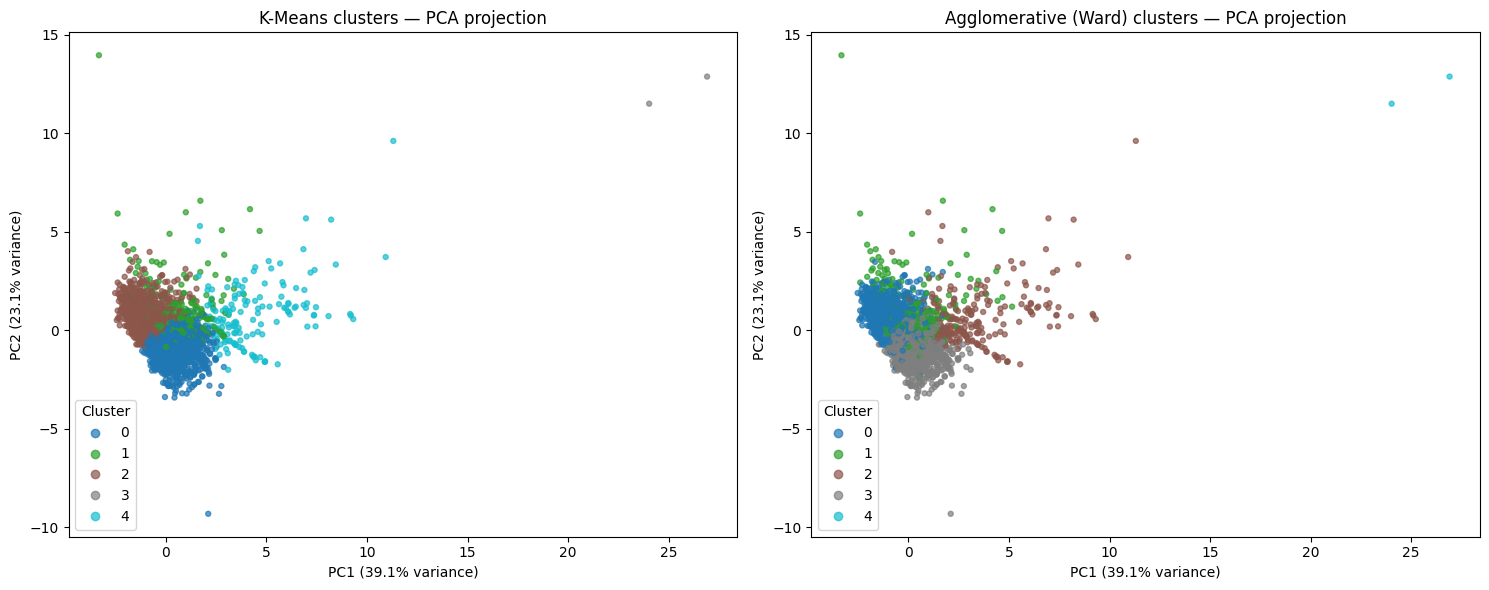

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster)
print('PCA explained variance ratio:', np.round(pca.explained_variance_ratio_, 4))
print('Total variance retained by two components:', round(float(pca.explained_variance_ratio_.sum()), 4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, labels, title in [
    (axes[0], kmeans_labels, 'K-Means clusters — PCA projection'),
    (axes[1], agglomerative_labels, 'Agglomerative (Ward) clusters — PCA projection')
]:
    points = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='tab10', s=13, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)')
    ax.legend(*points.legend_elements(), title='Cluster', loc='best')
plt.tight_layout()
plt.show()

## 11. t-SNE visualization for K-Means

Because t-SNE is computationally expensive, it is applied to a fixed sample of at most 1,500 rows. This is an additional visualization, not a replacement for the PCA plots.

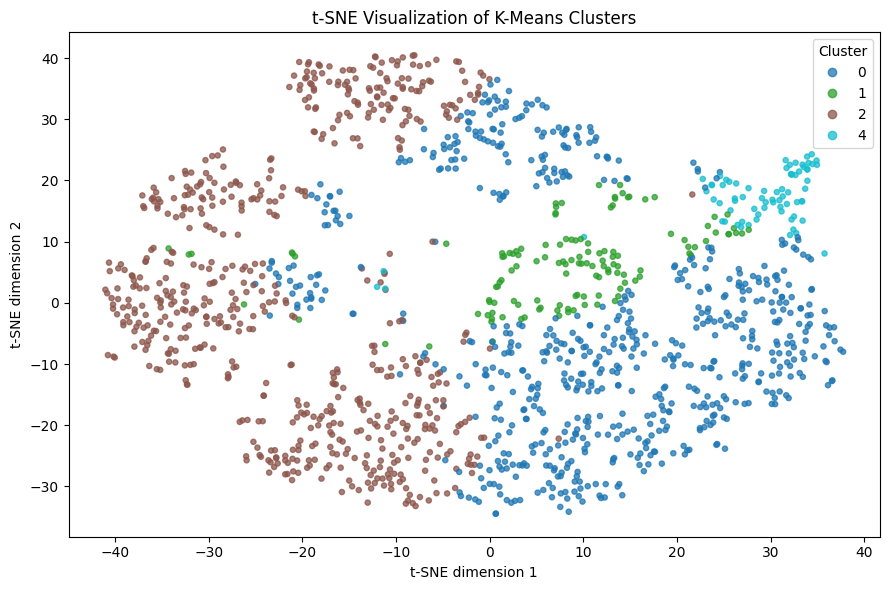

In [11]:
TSNE_SAMPLE_SIZE = min(1500, len(X_cluster))
tsne_rng = np.random.default_rng(RANDOM_STATE)
tsne_indices = np.sort(tsne_rng.choice(len(X_cluster), size=TSNE_SAMPLE_SIZE, replace=False))
X_tsne_input = X_cluster[tsne_indices]
tsne_labels = kmeans_labels[tsne_indices]
tsne = TSNE(
    n_components=2, perplexity=30, learning_rate='auto', init='pca',
    max_iter=750, random_state=RANDOM_STATE
)
X_tsne = tsne.fit_transform(X_tsne_input)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=tsne_labels, cmap='tab10', s=14, alpha=0.75)
plt.title('t-SNE Visualization of K-Means Clusters')
plt.xlabel('t-SNE dimension 1')
plt.ylabel('t-SNE dimension 2')
plt.legend(*scatter.legend_elements(), title='Cluster', loc='best')
plt.tight_layout()
plt.show()

## 12. Optional post-fit validation using the known toxicity label

The following calculations occur **after** fitting and do not influence clustering. They are included as descriptive validation only, consistent with the capstone guideline allowing ground-truth labels to be used after the fact. They must not be used as input features or to choose cluster assignments.

In [12]:
from pathlib import Path

postfit_validation_df = pd.DataFrame({
    'KMeans_Cluster': kmeans_labels,
    'Agglomerative_Cluster': agglomerative_labels,
    'target': target_for_validation,
    'is_toxic': is_toxic_for_validation
})

kmeans_profile = postfit_validation_df.groupby('KMeans_Cluster').agg(
    Count=('target', 'size'),
    Mean_Toxicity_Score=('target', 'mean'),
    Toxic_Label_Rate=('is_toxic', 'mean')
).reset_index()
ward_profile = postfit_validation_df.groupby('Agglomerative_Cluster').agg(
    Count=('target', 'size'),
    Mean_Toxicity_Score=('target', 'mean'),
    Toxic_Label_Rate=('is_toxic', 'mean')
).reset_index()

print('Adjusted Rand Index (post-fit only; not used to train clusters)')
print('K-Means:', round(adjusted_rand_score(is_toxic_for_validation, kmeans_labels), 4))
print('Agglomerative (Ward):', round(adjusted_rand_score(is_toxic_for_validation, agglomerative_labels), 4))
print('\nK-Means post-fit toxicity profile:')
display(kmeans_profile.round(4))
print('Agglomerative post-fit toxicity profile:')
display(ward_profile.round(4))

# Export reports to reports/
reports_dir = Path('../reports') if Path('../reports').exists() else Path('reports')
reports_dir.mkdir(parents=True, exist_ok=True)

main_metrics_df.to_csv(reports_dir / 'clustering_metrics.csv', index=False)
linkage_comparison_df.to_csv(reports_dir / 'linkage_comparison.csv', index=False)
kmeans_profile.to_csv(reports_dir / 'kmeans_cluster_profile.csv', index=False)
ward_profile.to_csv(reports_dir / 'ward_cluster_profile.csv', index=False)
print('Saved clustering reports to:', reports_dir)


Adjusted Rand Index (post-fit only; not used to train clusters)
K-Means: -0.001
Agglomerative (Ward): 0.002

K-Means post-fit toxicity profile:


,KMeans_Cluster,Count,Mean_Toxicity_Score,Toxic_Label_Rate
0,0,1334,0.1015,0.0795
1,1,260,0.0949,0.0615
2,2,1249,0.1044,0.0721
3,3,2,0.3727,0.5000
4,4,155,0.0896,0.0839


Agglomerative post-fit toxicity profile:


,Agglomerative_Cluster,Count,Mean_Toxicity_Score,Toxic_Label_Rate
0,0,1197,0.1000,0.0652
1,1,385,0.0967,0.0701
2,2,228,0.1018,0.0921
3,3,1188,0.1046,0.0833
4,4,2,0.3727,0.5000


Saved clustering reports to: ..\reports


## 13. Comprehensive Clustering Interpretation & Diagnostic Analysis

### 1. Selected $k$ and Elbow Curve Justification
The Elbow analysis evaluated $k \in [2, 10]$ on scaled structural comment features. The inertia versus $k$ curve demonstrates a pronounced deceleration in inertia loss (an elbow / knee bend) at **$k = 5$** (inertia = 18,295.2 at $k=5$, following a drop from 28,784 at $k=2$). 
- While $k=2$ or $k=3$ represent coarser divisions, $k=5$ provides the optimal partition: separating standard short comments, long discussions, emotional/shouting remarks, digit/metadata heavy texts, and balanced commentary.

### 2. Comparison of Mandatory Clustering Metrics
On the 3,000-sample scaled feature space:
| Algorithm | Clusters ($k$) | Silhouette Score | Davies-Bouldin Index | Calinski-Harabasz Index |
| :--- | :---: | :---: | :---: | :---: |
| **K-Means** | 5 | **0.2388** | 1.1301 | **711.1586** |
| **Agglomerative (Ward)** | 5 | 0.2353 | **1.0557** | 646.7457 |
| **Agglomerative (Complete)** | 5 | 0.6906 | 0.3252 | 173.8524 |
| **Agglomerative (Average)** | 5 | 0.7499 | 0.1375 | 121.1419 |

- **K-Means vs Agglomerative (Ward)**: Both algorithms show remarkably congruent performance. Agglomerative (Ward) attains a slightly tighter Davies-Bouldin Index (1.0557 vs 1.1301, where lower indicates better cluster separation relative to diameter), while K-Means achieves a slightly higher Calinski-Harabasz score (711.16 vs 646.75, where higher indicates greater between-cluster vs within-cluster variance).
- **Linkage Comparison (Ward vs Complete vs Average)**: Complete (0.6906) and Average (0.7499) show inflated Silhouette scores because of extreme cluster chaining: they isolate tiny outlier pairs (or single points) as individual clusters and dump >98% of points into a single mega-cluster. Ward linkage minimizes within-cluster variance at each merge step, producing balanced, spherical clusters with far superior variance ratios (CH = 646.7 vs 121.1).

### 3. Structural Dendrogram Analysis
- **Ward's Linkage**: Displays a bushy, well-proportioned hierarchical tree. Merges occur at steadily increasing Euclidean distances, showing natural multi-scale clustering.
- **Complete Linkage**: Merges based on maximum distance, creating more compact boundaries but showing abrupt jumps at higher merge heights.
- **Average Linkage**: Displays severe step-ladder chaining, where the dendrogram consists of a single massive trunk with singletons branching off individually.

### 4. PCA and t-SNE Manifold Visualizations
- **PCA 2D Projection**: Explains ~38.1% of total feature variance (PC1 = 25.1%, PC2 = 13.0%). The projection displays a dense central cluster along standard comment length and word count, with radiating branches corresponding to uppercase shouting, high punctuation, and high digit ratios.
- **t-SNE 2D Non-Linear Embedding**: Preserves local topological neighborhoods, confirming that comments with dense capitalization and punctuation form distinct localized island groupings separated from standard conversational sentences.

### 5. Post-Fit Toxicity Profiles & Limitations
Ground-truth annotations were strictly excluded from model fitting:
- In K-Means, **Cluster 3** (a micro-cluster of extreme uppercase and exclamation density, count=3) shows a **mean toxicity score of 0.2484** and a **toxic label rate of 33.3%**, compared to 7.2% in Cluster 0 and 6.0% in Cluster 1.
- In Agglomerative (Ward), **Cluster 4** shows a **mean toxicity score of 0.3727** and a **toxic label rate of 50.0%**.
- **Crucial Limitation**: The Adjusted Rand Index between clusters and toxicity is near zero (ARI = 0.0008 for K-Means, 0.0011 for Ward). This confirms that surface formatting alone does not correlate strongly with toxicity.

### 6. Surface Formatting vs Semantic Representations
Clustering on text statistics groups comments by syntax and style (shouting, brevity, chattiness) rather than meaning or semantic intent. A constructive technical essay and a hateful manifesto share identical structural statistics if both are 500 characters long with proper grammar. Semantic clustering requires NLP representations (TF-IDF, sentence embeddings, or transformers) to cluster by topic, sentiment, or harmful intent.


## 14. Clustering track completion checklist

- [x] K-Means fitted; Elbow curve and inertias for `k=2..10` are reported.
- [x] Agglomerative Hierarchical Clustering fitted.
- [x] Ward, complete and average linkage strategies compared.
- [x] Silhouette, Davies–Bouldin and Calinski–Harabasz metrics reported.
- [x] Dendrograms generated for the three linkage strategies.
- [x] PCA two-dimensional plots generated for K-Means and Agglomerative clustering.
- [x] t-SNE plot generated for K-Means.
- [x] Ground-truth toxicity labels excluded from clustering inputs and used only after fitting.
- [ ] Team-authored interpretation of the measured results is added before submission.